## Trace driven simulation
### The first part is indoor trace driven simulation

In [9]:
# read complex data from .dat file
from tracemalloc import stop
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
from read_raw_data import read_dat_file 

iq0_path = '/home/ishani/LeoPNT/USRP_data/12_2/time_19_45_freq_11_0G_bw_2.0M_inrx0.dat'
iq1_path = '/home/ishani/LeoPNT/USRP_data/12_2/time_19_45_freq_11_0G_bw_2.0M_inrx1.dat'
iq2_path = '/home/ishani/LeoPNT/USRP_data/12_2/time_19_45_freq_11_0G_bw_2.0M_inrx2.dat'

# we have 3 synchronized LNBs, placed in the following way:
#  ------------         N
# | LNB2 LNB0 |       W + E
# | LNB1      |         S
#  ------------

start_idx = int(1e5)
stop_idx = int(6e5)
iq0 =  read_dat_file(iq0_path, start_idx, stop_idx)
iq1 = read_dat_file(iq1_path, start_idx, stop_idx)
iq2 = read_dat_file(iq2_path, start_idx, stop_idx)

# converting to received signal format 
received_sig = np.zeros((3,len(iq0)), dtype=complex)
received_sig[0] = iq0   
received_sig[1] = iq1
received_sig[2] = iq2

500000 (500000,)
500000 (500000,)
500000 (500000,)


In [3]:
del_phi0 = np.unwrap(np.angle(iq1) - np.angle(iq2))
del_phi1 = np.unwrap(np.angle(iq2) - np.angle(iq0))
# low pass filter for average ever 1000 samples
del_phi0 = signal.filtfilt([1/1000]*1000, 1, del_phi0)
del_phi1 = signal.filtfilt([1/1000]*1000, 1, del_phi1)

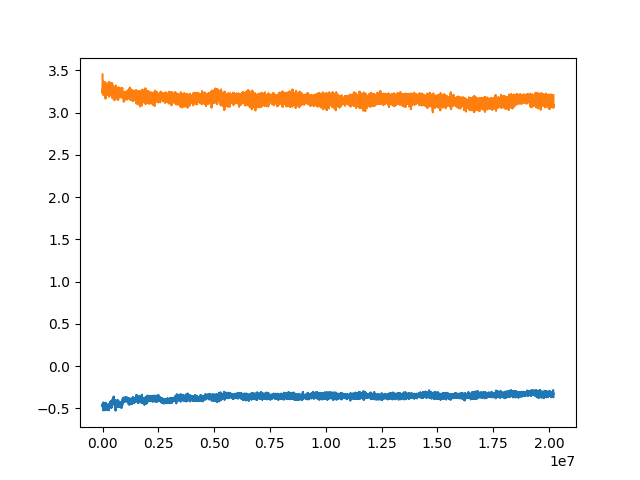

In [4]:
import matplotlib.pyplot as plt
%matplotlib widget

plt.figure()
plt.plot(del_phi0)
plt.plot(del_phi1)
plt.show()

In [12]:
# calculate the angle of arrival give the spacing between the antennas
# and the wavelength of the signal
c = 3e8
fc = 11e9
lam = c/fc
d0 = 0.20 # vertical distance between LNB0 and LNB2
d1 = 0.135 # horizontal distance between LNB0 and LNB1

vertical_ambiguity = int(d0/(lam/2))
horizontal_ambiguity = int(d1/(lam/2))
num_ambiguity = vertical_ambiguity*horizontal_ambiguity

In [ ]:
del_phi_0 = np.zeros((vertical_ambiguity, iq0.shape[0]))
del_phi_1 = np.zeros((horizontal_ambiguity, iq0.shape[0]))
pattern_0 = np.unwrap(np.angle(iq0/iq2))
pattern_1 = np.unwrap(np.angle(received_sig[0,:]/received_sig[2,:]))
vertical_phi_bound = np.pi*vertical_ambiguity
horizontal_phi_bound = np.pi*horizontal_ambiguity

Text(0, 0.5, 'Elevation')

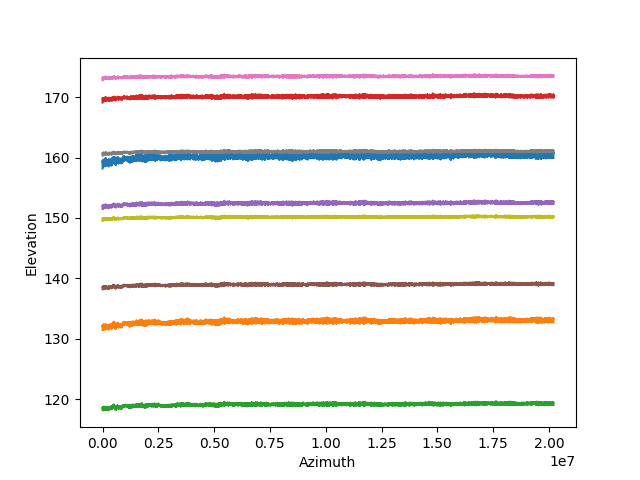

In [16]:
# calculating the angle of arrival
plt.figure()
for i in k0[0:3]:
    for j in k1[0:3]:
        phi0 = del_phi0 + 2*np.pi*i
        phi1 = del_phi1 + 2*np.pi*j

        az = np.arctan2(-d0*phi0,d1*phi1)
        el = np.arccos(phi0*lam/(2*np.pi*d0*np.sin(az)))
        az = np.unwrap(-az+np.pi/2)
        # az = np.where(az%(2*np.pi)<0, 2*np.pi-np.abs(az), az%(2*np.pi))

        # a = (np.arctan(phi1/phi0))
        # el = np.arccos(phi0*lam/(2*np.pi*d0*np.cos(a)))
        # az = np.arctan2(phi1, phi0)
        # plt.plot(np.rad2deg(az), label = str(i)+','+str(j))
        plt.plot(np.rad2deg(az),np.rad2deg(el),'.')
        # plt.hlines(np.rad2deg(),0,len(az))
plt.xlabel('Azimuth')
plt.ylabel('Elevation')

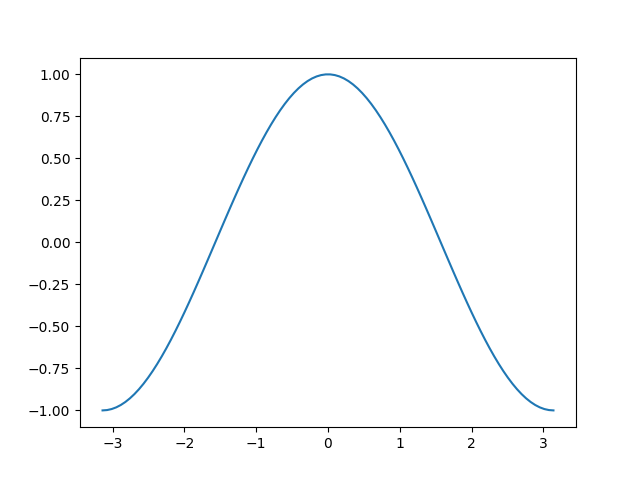

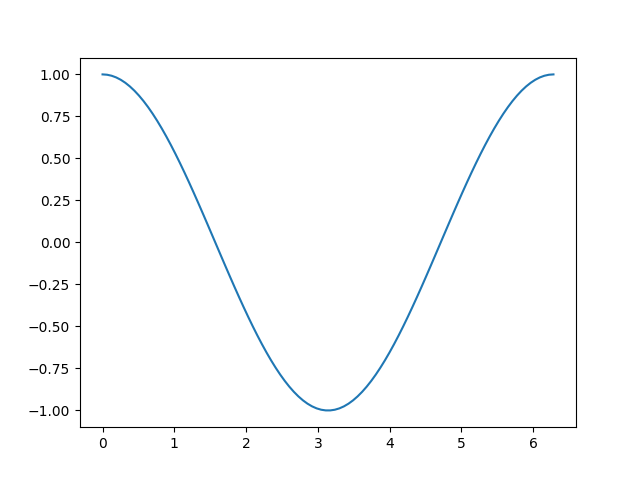

In [10]:
ang = np.linspace(-np.pi,np.pi,100)
plt.figure()
plt.plot(ang,np.cos(ang))
plt.show()
plt.figure()
ang_ = np.linspace(0,2*np.pi,100)
plt.plot(ang_,np.cos(ang_))
plt.show()

In [9]:
import numpy as np
np.cos(-np.pi/3+2*np.pi)

0.5000000000000001

In [12]:
1//1

1